# День 08. Упражнение 02
# Мульти-классовая классификация. One-hot кодирование. Случайный лес

## 0. Импорты

In [268]:
import pandas as pd
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt
from sklearn.svm import SVC
from sklearn.multiclass import OneVsRestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier


## 1. Предобработка


1. Прочитай файл [`checker-submits.csv`](https://drive.google.com/file/d/14voc4fNJZiLEFaZyd8nEG-lQt5JjatYw/view?usp=sharing).
2. Создай DataFrame `df` с колонками: `uid`, `labname`, `numTrials`, `hour`, `dayofweek`, где `hour` извлекается из `timestamp`, а также `dayofweek` (`0` — понедельник, `6` — воскресенье). Мы будем пытаться предсказать день недели, имея данные о том, какой пользователь сделал коммит, для какой лабораторной, в какой час и с какой попытки.
3. С помощью `OneHotEncoder()` преобразуй категориальные признаки, затем удали из DataFrame исходные столбцы.
4. Используй `StandardScaler()` и нормализуй числовые признаки.
5. Сохрани DataFrame как `dayofweek.csv`.
6. Перед тем как пробовать разные алгоритмы, вычисли точность наивного алгоритма — того, который предсказывает всё как самый частый класс.


In [249]:
df = pd.read_csv("../data/checker_submits.csv")
df["timestamp"] = pd.to_datetime(df["timestamp"])
df["hour"] = df["timestamp"].dt.hour
df["dayofweek"] = df["timestamp"].dt.dayofweek
df = df.drop(columns=["timestamp"])
df.head()

,uid,labname,numTrials,hour,dayofweek
0,user_4,project1,1,5,4
1,user_4,project1,2,5,4
2,user_4,project1,3,5,4
3,user_4,project1,4,5,4
4,user_4,project1,5,5,4


In [250]:
# Начинаем работу с onehotencoder
#преобразовали uid
encoder_uid = OneHotEncoder(sparse_output=False)
encoded_uid = encoder_uid.fit_transform(df[["uid"]])
names = encoder_uid.get_feature_names_out()
encoded_df = pd.DataFrame(
    encoded_uid,
    columns=names,
    index=df.index
)
df = pd.concat([df, encoded_df], axis=1)
df


,uid,labname,numTrials,hour,dayofweek,uid_user_0,uid_user_1,uid_user_10,uid_user_11,uid_user_12,...,uid_user_27,uid_user_28,uid_user_29,uid_user_3,uid_user_30,uid_user_31,uid_user_4,uid_user_6,uid_user_7,uid_user_8
0,user_4,project1,1,5,4,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
1,user_4,project1,2,5,4,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
2,user_4,project1,3,5,4,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
3,user_4,project1,4,5,4,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
4,user_4,project1,5,5,4,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1681,user_19,laba06s,9,20,3,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1682,user_1,laba06s,6,20,3,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1683,user_1,laba06s,7,20,3,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1684,user_1,laba06s,8,20,3,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [251]:
# Преобразуем labname
encoder_lab = OneHotEncoder(sparse_output=False)
encoded_lab = encoder_lab.fit_transform(df[["labname"]])
names_2 = encoder_lab.get_feature_names_out()
encoded_df_2 = pd.DataFrame(
    encoded_lab,
    columns=names_2,
    index=df.index
)
df = pd.concat([df, encoded_df_2], axis=1)

# удаляем лишние столбцы
df = df.drop(columns=["labname", "uid"])
df.columns


Index(['numTrials', 'hour', 'dayofweek', 'uid_user_0', 'uid_user_1',
       'uid_user_10', 'uid_user_11', 'uid_user_12', 'uid_user_13',
       'uid_user_14', 'uid_user_15', 'uid_user_16', 'uid_user_17',
       'uid_user_18', 'uid_user_19', 'uid_user_2', 'uid_user_20',
       'uid_user_21', 'uid_user_22', 'uid_user_23', 'uid_user_24',
       'uid_user_25', 'uid_user_26', 'uid_user_27', 'uid_user_28',
       'uid_user_29', 'uid_user_3', 'uid_user_30', 'uid_user_31', 'uid_user_4',
       'uid_user_6', 'uid_user_7', 'uid_user_8', 'labname_code_rvw',
       'labname_lab02', 'labname_lab03', 'labname_lab03s', 'labname_lab05s',
       'labname_laba04', 'labname_laba04s', 'labname_laba05', 'labname_laba06',
       'labname_laba06s', 'labname_project1'],
      dtype='str')

In [252]:
# Нормализовываем числовые признаки используя standartscaler
scaler = StandardScaler()
scaler_X = scaler.fit_transform(df[["hour", "numTrials"]])
df[["hour", "numTrials"]] = scaler_X
df.to_csv("dayofweek.csv",index=False)



In [253]:
#Вычисляем точность наивного алгоритма
mc = df["dayofweek"].mode()
df["mc"] = mc[0]
mode = len(df[df["dayofweek"] == mc[0]])
n_accuracy = mode / len(df)
df = df.drop(columns=["mc"])
n_accuracy


0.23487544483985764

## 2. Алгоритмы


### a. Логистическая регрессия

1. Обучи логистическую регрессию; для базовой модели используй `random_state=21`, `fit_intercept=False`.
2. Вычисли точность (accuracy).
3. Напиши функцию, которая строит график (`barh`), принимая коэффициенты обученной модели, имена признаков и количество `top-n` наиболее важных признаков для отображения.
4. Построй график (`barh`) для базовой модели с 10 самыми важными признаками (по абсолютному значению) для обученной модели.
5. Помни, что это мульти-классовая классификация, и `coef_` возвращает матрицу — чтобы вычислить важность признака, нужно просуммировать все индивидуальные значения важности этого признака для всех целевых классов.

In [254]:
X_df = df.drop(columns=["dayofweek"])
logmodel = LogisticRegression(random_state=21, fit_intercept=False)
logmodel.fit(X_df, df["dayofweek"])
day_predict = logmodel.predict(X_df)
ac = accuracy_score(df["dayofweek"], day_predict)



In [255]:
# готовим данные для построения графика
coefs = logmodel.coef_
feature_names = X_df.columns
#Вычисляем важность признаков
bul_df = pd.DataFrame(abs(coefs), columns=X_df.columns)
top = bul_df.sum(axis=0).sort_values(ascending=False)
top

uid_user_14         9.755182
labname_laba06s     8.855578
labname_code_rvw    8.051536
uid_user_2          7.889630
labname_laba06      7.809796
uid_user_3          7.567023
labname_laba05      7.496376
uid_user_26         7.084833
uid_user_4          6.953176
uid_user_17         6.685332
uid_user_24         6.601262
uid_user_1          6.531716
uid_user_27         6.335150
uid_user_13         6.234259
uid_user_10         6.128889
uid_user_21         6.117150
uid_user_29         5.941366
uid_user_8          5.934209
uid_user_31         5.803001
uid_user_16         5.676753
uid_user_18         5.458192
labname_lab05s      5.272662
uid_user_19         5.192751
uid_user_12         5.095684
uid_user_20         4.814923
labname_project1    4.795120
uid_user_28         4.630236
uid_user_25         4.408974
labname_laba04s     4.316149
uid_user_11         4.222872
labname_laba04      4.093281
numTrials           4.024883
uid_user_15         3.682300
uid_user_22         3.630463
uid_user_23   

In [256]:
def barh(coefs, names, topn):
    bul_df = pd.DataFrame(abs(coefs), columns=names)
    top = bul_df.sum(axis=0).sort_values(ascending=False)
    top_10 = top.head(topn)
    plt.figure(figsize=(8,4))
    plt.xlabel("Важность")
    plt.ylabel("Признак")
    plt.title("Наиболее важные признаки")
    plt.barh(top_10.index, top_10.values)
    

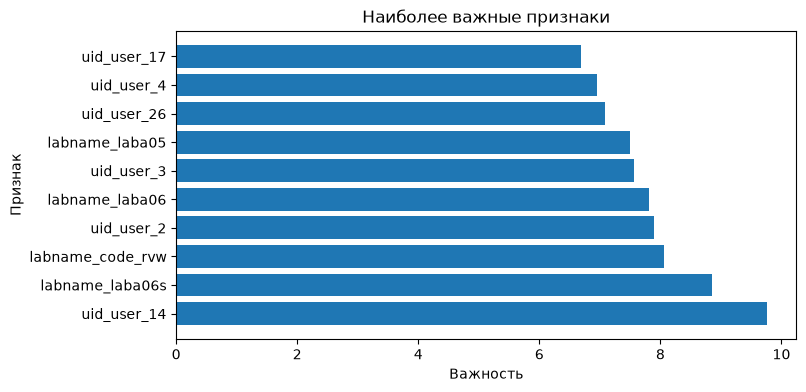

In [257]:
barh(logmodel.coef_, X_df.columns, 10)

### b. SVC

1. Обучи модель `SVC`; для базовой модели используй параметры `kernel='linear'`, `probability=True`, `random_state=21`.
2. Попробуй разные ядра, вычисли точности.
3. Построй график (`barh`) для базовой модели с 10 самыми важными признаками (по абсолютному значению) для обученной модели с линейным ядром.*

*По умолчанию SVC использует стратегию “one vs one” для классификации, поэтому в `coef_` возвращает матрицу. Чтобы вычислить важность признака, нужно использовать [OneVsRestClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.multiclass.OneVsRestClassifier.html) поверх SVC и просуммировать все индивидуальные значения важности признака для всех целевых классов.

In [258]:
#Обучаем модель и пробуем разные ядра
svc_model = SVC(kernel='linear', probability=True, random_state=21)
svc_model.fit(X_df, df["dayofweek"])
y_pred = svc_model.predict(X_df)
ac = accuracy_score(df["dayofweek"], y_pred)
ac


/Users/a1111/Desktop/DSB10_Intro_to_ML_ID_1577653-1/src/venv/lib/python3.14/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


0.702846975088968

In [259]:
svc_model = SVC(kernel='rbf', probability=True, random_state=21)
svc_model.fit(X_df, df["dayofweek"])
y_pred = svc_model.predict(X_df)
ac = accuracy_score(df["dayofweek"], y_pred)
ac

/Users/a1111/Desktop/DSB10_Intro_to_ML_ID_1577653-1/src/venv/lib/python3.14/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


0.8558718861209964

In [260]:
svc_model = SVC(kernel='poly', probability=True, random_state=21)
svc_model.fit(X_df, df["dayofweek"])
y_pred = svc_model.predict(X_df)
ac = accuracy_score(df["dayofweek"], y_pred)
ac

/Users/a1111/Desktop/DSB10_Intro_to_ML_ID_1577653-1/src/venv/lib/python3.14/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


0.8594306049822064

In [261]:
svc_model = SVC(kernel='sigmoid', probability=True, random_state=21)
svc_model.fit(X_df, df["dayofweek"])
y_pred = svc_model.predict(X_df)
ac = accuracy_score(df["dayofweek"], y_pred)
ac

/Users/a1111/Desktop/DSB10_Intro_to_ML_ID_1577653-1/src/venv/lib/python3.14/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


0.3997627520759193

In [262]:
# Создаем обертку для линейного ядра
svc_model = OneVsRestClassifier(SVC(kernel='linear', probability=True, random_state=21))
svc_model.fit(X_df, df["dayofweek"])
y_pred = svc_model.predict(X_df)
ac = accuracy_score(df["dayofweek"], y_pred)
print(ac)
#создаем пустой список, он будет хранить строки коэфициентов
rows = []
for i in range(len(svc_model.estimators_)):
    rows.append(svc_model.estimators_[i].coef_[0])
print(rows)
# Превращаем список в таблицу
coef_df = pd.DataFrame(rows, columns=X_df.columns)
coef_df.shape

/Users/a1111/Desktop/DSB10_Intro_to_ML_ID_1577653-1/src/venv/lib/python3.14/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/Users/a1111/Desktop/DSB10_Intro_to_ML_ID_1577653-1/src/venv/lib/python3.14/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/Users/a1111/Desktop/DSB10_Intro_to_ML_ID_1577653-1/src/venv/lib/python3.14/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/Users/a1111/Desktop/DSB10_Intro_t

0.6115065243179122
[array([-1.76361137e-04,  2.67236773e-05,  8.10446643e-01, -2.81513304e-02,
       -2.78620268e-02, -2.82013818e-02, -2.79538413e-02, -2.77896863e-02,
       -2.79562239e-02, -2.79686234e-02, -2.79623782e-02, -2.78769990e-02,
       -2.79074440e-02, -2.79395270e-02, -2.78101298e-02, -2.79522714e-02,
       -2.80178998e-02, -2.76891498e-02, -2.77084854e-02, -2.78388729e-02,
       -2.79016767e-02, -2.82887246e-02, -2.78947601e-02, -2.81606967e-02,
       -2.78144923e-02, -2.77681798e-02, -2.78420939e-02, -2.79608791e-02,
       -2.78304611e-02, -2.79852520e-02, -2.81843812e-02, -2.82287743e-02,
       -3.51254414e-01,  8.10446643e-01,  1.00000000e+00,  1.00000000e+00,
       -3.51458555e-01, -3.51144166e-01, -3.51376237e-01, -3.51670676e-01,
       -3.51223268e-01, -3.51224037e-01, -3.51095290e-01]), array([ 9.49476041e-05, -3.46367093e-04,  0.00000000e+00, -2.31077038e-01,
       -2.30323701e-01, -2.29966850e-01, -2.29971779e-01,  1.76865148e+00,
       -2.29966860e-

(7, 43)

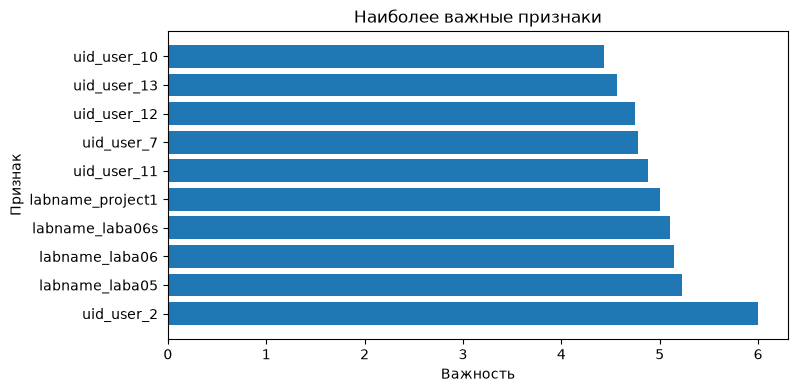

In [263]:
barh(coef_df, X_df.columns, 10)

### c. Дерево решений

1. Обучи `DecisionTreeClassifier`; для базовой модели используй `max_depth=4`, `random_state=21`.
2. Попробуй разные значения `max_depth`, вычисли точности.
3. Построй график (`barh`) для базовой модели с 10 самыми важными признаками (по абсолютному значению) для обученной модели, используя написанную функцию.

In [264]:
tree_model_4 = DecisionTreeClassifier(max_depth=4, random_state=21)
tree_model_4.fit(X_df, df["dayofweek"])
y_pred = tree_model_4.predict(X_df)
ac_4 = accuracy_score(df["dayofweek"], y_pred)
print(ac_4)

0.5516014234875445


In [265]:
tree_model = DecisionTreeClassifier(max_depth=5, random_state=21)
tree_model.fit(X_df, df["dayofweek"])
y_pred = tree_model.predict(X_df)
ac = accuracy_score(df["dayofweek"], y_pred)
print(ac)

0.6109134045077106


1.0


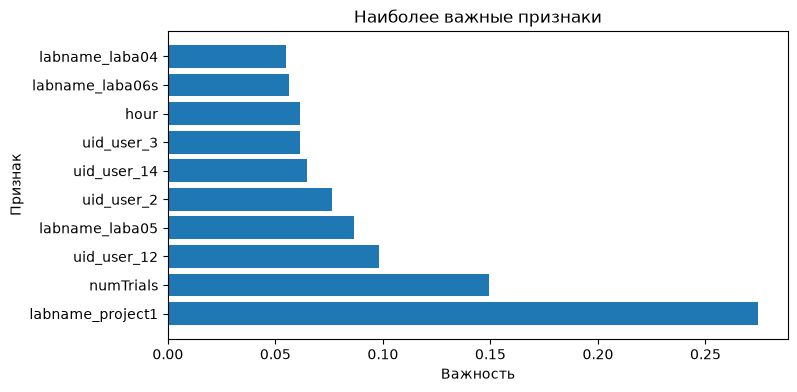

In [266]:
tree_model = DecisionTreeClassifier(max_depth=28, random_state=21)
tree_model.fit(X_df, df["dayofweek"])
y_pred = tree_model.predict(X_df)
ac = accuracy_score(df["dayofweek"], y_pred)
print(ac)
barh(tree_model_4.feature_importances_.reshape(1, -1), X_df.columns, 10)

### d. Случайный лес

В реальной жизни лес состоит из множества деревьев. То же самое и в машинном обучении: случайный лес — это набор отдельных деревьев решений (подробнее см. документацию).

1. Обучи `RandomForestClassifier`; для базовой модели используй параметры `n_estimators=100`, `max_depth=25`, `random_state=21`.
2. Попробуй разные значения `max_depth` и `n_estimators`, вычисли точности.
3. Построй график (`barh`) для базовой модели с 10 самыми важными признаками (по абсолютному значению) для обученной модели, используя написанную функцию.

In [269]:
ranf_model = RandomForestClassifier(n_estimators=100, max_depth=25, random_state=21)
ranf_model.fit(X_df, df["dayofweek"])
y_pred = ranf_model.predict(X_df)
ac = accuracy_score(df["dayofweek"], y_pred)
print(ac)

1.0


In [ ]:
ranf_model = RandomForestClassifier(n_estimators=5, max_depth=15, random_state=21)
ranf_model.fit(X_df, df["dayofweek"])
y_pred = ranf_model.predict(X_df)
ac = accuracy_score(df["dayofweek"], y_pred)
print(ac)

0.9531435349940688


1.0


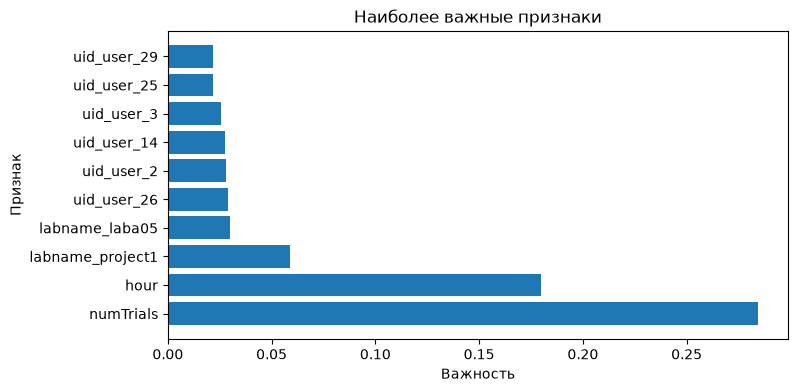

In [273]:
ranf_model = RandomForestClassifier(n_estimators=100, max_depth=25, random_state=21)
ranf_model.fit(X_df, df["dayofweek"])
y_pred = ranf_model.predict(X_df)
ac = accuracy_score(df["dayofweek"], y_pred)
print(ac)

barh(ranf_model.feature_importances_.reshape(1,-1), X_df.columns, 10)